# Notebook 1 · Converser et se souvenir

*Formation « Comprendre et développer des agents IA spécialisés », module 1.*

**MégaShop** est une boutique en ligne d'articles du quotidien : smartphones, écouteurs, baskets, vêtements, sacs. Elle veut une conseillère virtuelle, **Léa**, qui discute avec les clients **et se souvient d'eux** : si Sofia dit qu'elle chausse du 42, elle ne veut pas le répéter à chaque message, ni la semaine suivante.

<p align="center"><img src="assets/diagrams/nb1_histoire_sofia.png" alt="Deux échelles de mémoire : dans la même conversation, puis la semaine suivante. Sans mémoire, Léa redemande ou répond de façon générique ; avec mémoire, elle se souvient de la pointure 42 et du budget de Sofia" width="1000"></p>

Dans ce notebook, on découvre comment fonctionne un **LLM**, puis on lui donne une **mémoire**. Chaque notion est d'abord montrée **en Python pur**, puis **avec LangChain ou LangGraph**.

Exécute les cellules dans l'ordre (`Maj + Entrée`). Tout est dans ce notebook.

---
## Étape 0 · Configuration

**Objectif** : se connecter à OpenAI.

La clé API se met dans un fichier `.env` à la racine du dossier : `OPENAI_API_KEY=sk-...`

On utilise **`gpt-4.1-mini`** : il est rapide, il permet de régler la **température** et de voir les **probabilités** des tokens, deux notions explorées plus loin.

In [1]:
import os, math
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()
assert os.getenv("OPENAI_API_KEY"), "Ajoute OPENAI_API_KEY=sk-... dans le fichier .env, puis redémarre le noyau"

client = OpenAI()
MODELE = "gpt-4.1-mini"
print(f"Connecté à OpenAI : {MODELE}")

Connecté à OpenAI : gpt-4.1-mini


---
## Étape 1 · Un LLM lit des tokens, pas des mots

**Objectif** : voir comment un LLM « lit » un texte.

Un LLM découpe d'abord le texte en **tokens** : un mot entier, un bout de mot, un espace, un symbole.

In [2]:
import tiktoken
encodeur = tiktoken.get_encoding("o200k_base")       # le découpage des modèles GPT-4o, 4.1 et 5

texte = "Les Nike Air Force 1 blanches sont à 119,99 € chez MégaShop."
tokens = encodeur.encode(texte)

print(f"{len(texte)} caractères → {len(tokens)} tokens\n")
print(" | ".join(encodeur.decode([t]) for t in tokens))

60 caractères → 20 tokens

Les |  Nike |  Air |  Force |   | 1 |  bl | anches |  sont |  à |   | 119 | , | 99 |  € |  chez |  Mé | ga | Shop | .


Voici le même résultat, étape par étape : le texte devient une suite de tokens, puis une suite de nombres.

<p align="center"><img src="assets/diagrams/nb1_lecture_tokens.png" alt="Le texte « Les Nike Air Force 1 blanches sont à 119,99 € chez MégaShop. » est découpé en 20 tokens, chacun converti en numéro, puis transmis au LLM" width="960"></p>

Les mots courants forment **un seul token**, alors que les mots rares ou les noms de marque sont **coupés en morceaux**.

Comparons quelques phrases :

In [3]:
phrases = ["Bonjour, je cherche des baskets.",
           "Hello, I am looking for sneakers.",
           "anticonstitutionnellement",
           "😍👟🔥"]
for phrase in phrases:
    print(f"{len(encodeur.encode(phrase)):>3} tokens │ {phrase}")

  7 tokens │ Bonjour, je cherche des baskets.
  8 tokens │ Hello, I am looking for sneakers.
  5 tokens │ anticonstitutionnellement
  4 tokens │ 😍👟🔥


**À retenir**
- Un LLM lit des **tokens**. Ordre de grandeur : 1 token ≈ ¾ de mot en anglais courant. En français, c'est variable et souvent un peu plus.
- Le français coûte un peu plus de tokens que l'anglais, et les emojis sont coûteux.
- Les tokens sont l'**unité de coût** (on paie à l'envoi comme à la réception) et de **limite** (un LLM ne lit qu'un nombre limité de tokens à la fois).

---
## Étape 2 · Il prédit le token suivant

**Objectif** : comprendre comment un LLM « écrit ».

Un LLM ne « réfléchit » pas comme nous : il calcule **quel token a le plus de chances de venir ensuite**, l'ajoute, puis recommence, token après token.

<p align="center"><img src="assets/diagrams/nb1_generation_token.png" alt="Un LLM écrit token par token : découpage du texte, probabilités des candidats, choix, puis on recommence" width="920"></p>

On peut demander à OpenAI de nous montrer ces **probabilités** :

In [4]:
reponse = client.chat.completions.create(
    model=MODELE,
    messages=[{"role": "system", "content": "Continue la phrase. Écris uniquement le mot suivant."},
              {"role": "user", "content": "Pour aller courir, j'achète une paire de"}],
    max_tokens=1, logprobs=True, top_logprobs=5, temperature=0,
)
for candidat in reponse.choices[0].logprobs.content[0].top_logprobs:
    proba = math.exp(candidat.logprob)                # logprob -> probabilité entre 0 et 1
    print(f"{candidat.token!r:<14} {'█' * round(proba * 40):<40} {proba:.0%}")

'cha'          ███████████████████████████              68%
'b'            █████████████                            32%
' chaussures'                                           0%
'basket'                                                0%
'chaus'                                                 0%


Le LLM hésite entre `'cha'` (le début de **cha**ussures) et `'b'` (le début de **b**askets). Il ne choisit pas un mot, il choisit un **token**.

**Attention** : Ces probabilités valent **pour ce contexte précis** (cette consigne, cette phrase), et on ne voit que les 5 premiers candidats parmi des dizaines de milliers.

### La température : prudent ou créatif ?

La **température** règle la façon de choisir parmi ces candidats :
- **0** : toujours le plus probable. C'est stable et répétable, idéal pour une réponse de SAV.
- **1 ou plus** : on tire au sort, et les candidats moins probables ont leur chance. C'est créatif et varié, idéal pour du marketing.

Demandons 3 slogans publicitaires avec chaque réglage :

In [5]:
consigne = "Écris un slogan de 8 mots maximum pour le hoodie Adidas vendu par MégaShop."

for temperature in (0, 1.3):
    print(f"\nTempérature {temperature}")
    for _ in range(3):
        r = client.chat.completions.create(model=MODELE, temperature=temperature,
                                           messages=[{"role": "user", "content": consigne}])
        print("   •", r.choices[0].message.content)


Température 0
   • Adidas chez MégaShop : style et confort garantis !
   • Adidas chez MégaShop : style et confort garantis !
   • Adidas chez MégaShop : style et confort garantis !

Température 1.3
   • Confort Adidas, style unique – seulement chez MégaShop!
   • Adidas chez MégaShop : style et confort garantis !
   • Adopte le style, choisis Adidas chez MégaShop!


**À retenir**
- Un LLM écrit **token par token**, en choisissant parmi les plus probables.
- **Température basse** = réponses stables (SAV, données). **Température haute** = réponses variées (slogans, idées).
- **À savoir** : Sur certains modèles « de raisonnement » (par exemple `gpt-5-mini`, en octobre 2026), la température n'est pas réglable. Ces options évoluent : vérifie la documentation du modèle choisi.

---
## Étape 3 · Parler à un LLM : les rôles

**Objectif** : donner une personnalité à Léa.

On envoie au LLM une **liste de messages**, chacun avec un **rôle** : `system` (le développeur), `user` (le client) ou `assistant` (le LLM).

<p align="center"><img src="assets/diagrams/nb1_roles_messages.png" alt="Liste de messages system et user envoyée au LLM, qui répond avec un message assistant" width="760"></p>

Le **prompt système** est invisible pour le client, mais il guide toutes les réponses.

In [6]:
SYSTEME = """Tu es Léa, conseillère de vente de MégaShop, boutique en ligne d'articles du quotidien
(smartphones, écouteurs, baskets, vêtements, sacs). Tu vouvoies toujours le client.
Réponds en français, en 3 phrases maximum, avec un ton chaleureux."""

messages = [{"role": "system", "content": SYSTEME},
            {"role": "user", "content": "Bonjour ! Vous pouvez m'aider à choisir un cadeau ?"}]

reponse = client.chat.completions.create(model=MODELE, messages=messages)
print("Léa :", reponse.choices[0].message.content)
print(f"\n{reponse.usage.prompt_tokens} tokens envoyés, {reponse.usage.completion_tokens} tokens reçus")

Léa : Bonjour ! Avec plaisir, quel type de cadeau cherchez-vous et pour quelle occasion ? Je suis là pour vous conseiller selon vos envies et votre budget.

83 tokens envoyés, 29 tokens reçus


### Avec LangChain

LangChain propose une interface **identique pour tous les fournisseurs** (OpenAI, Anthropic, Mistral, Ollama...). Pour changer de fournisseur, tu changes une seule ligne.

In [7]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model=MODELE)
reponse = llm.invoke([("system", SYSTEME), ("user", "Bonjour ! Vous pouvez m'aider à choisir un cadeau ?")])
print("Léa :", reponse.content)

Léa : Bonjour ! Avec plaisir, quel type de cadeau recherchez-vous et pour quelle occasion ? Je suis là pour vous conseiller parmi nos smartphones, écouteurs, baskets, vêtements ou sacs.


**À retenir**
- On parle à un LLM avec une **liste de messages** : `system`, `user`, `assistant`.
- Le **prompt système** définit la personnalité et les règles de Léa.

---
## Étape 4 · Le problème : un LLM n'a pas de mémoire

**Objectif** : constater que chaque appel repart de zéro.

Sofia se présente, puis pose une deuxième question **dans un appel séparé** :

In [8]:
def demander(question):
    """Un appel isolé : on n'envoie QUE le prompt système et la question."""
    r = client.chat.completions.create(model=MODELE, messages=[{"role": "system", "content": SYSTEME},
                                                              {"role": "user", "content": question}])
    return r.choices[0].message.content

for question in ["Bonjour, je m'appelle Sofia et je chausse du 42.", "Vous vous souvenez de ma pointure ?"]:
    print(f"Sofia : {question}\nLéa   : {demander(question)}\n")

Sofia : Bonjour, je m'appelle Sofia et je chausse du 42.
Léa   : Bonjour Sofia, ravie de vous aider ! Nous avons une belle sélection de baskets en taille 42, souhaitez-vous que je vous recommande des modèles en particulier ?

Sofia : Vous vous souvenez de ma pointure ?
Léa   : Bonjour ! Pourriez-vous me rappeler votre pointure afin que je vérifie nos articles disponibles ? Je suis là pour vous aider à trouver la paire parfaite.



**Léa a déjà oublié !** Un LLM est **sans état** : il ne garde rien d'un appel à l'autre. Le modèle ne reçoit que **les messages que ton programme lui transmet lors de cet appel**. Rien d'autre.

### Le schéma à garder en tête pour la suite

<p align="center"><img src="assets/diagrams/nb1_architecture_memoire.png" alt="Le client parle à l'application, qui stocke la mémoire hors du LLM et envoie un contexte choisi au LLM" width="860"></p>

**À retenir**
- La mémoire n'est **pas dans le LLM**. C'est **l'application** (ton code) qui la stocke, la relit, et choisit quoi envoyer au modèle.

---
## Étape 5 · Donner une mémoire : l'historique

**Objectif** : faire en sorte que Léa se souvienne de la conversation.

L'astuce est simple : **à chaque message, on renvoie toute la conversation**.

```
Appel 1 : [système] [Sofia : je chausse du 42]
Appel 2 : [système] [Sofia : je chausse du 42] [Léa : ...] [Sofia : ma pointure ?]
```

<p align="center"><img src="assets/diagrams/nb1_historique_messages.png" alt="Trois appels successifs : chaque appel renvoie toute la conversation, et le nombre de tokens envoyés passe de 86 à 140 puis 201" width="860"></p>

### En Python pur : une liste qu'on remplit

In [9]:
historique = [{"role": "system", "content": SYSTEME}]
tokens_envoyes = []                                                          # pour la courbe de l'étape 6

def discuter(message_client):
    historique.append({"role": "user", "content": message_client})          # 1. on ajoute le message
    r = client.chat.completions.create(model=MODELE, messages=historique)    # 2. on envoie TOUT l'historique
    reponse = r.choices[0].message.content
    historique.append({"role": "assistant", "content": reponse})             # 3. on garde la réponse
    tokens_envoyes.append(r.usage.prompt_tokens)
    print(f"Client : {message_client}\nLéa : {reponse}\n   {r.usage.prompt_tokens} tokens envoyés\n")

discuter("Bonjour, je m'appelle Sofia et je chausse du 42.")
discuter("Vous vous souvenez de ma pointure ?")

Client : Bonjour, je m'appelle Sofia et je chausse du 42.
Léa : Bonjour Sofia, je suis ravie de vous aider ! Souhaitez-vous découvrir notre sélection de baskets en taille 42 ? N’hésitez pas à me dire ce que vous cherchez exactement.
   86 tokens envoyés

Client : Vous vous souvenez de ma pointure ?
Léa : Bonjour Sofia, oui bien sûr, vous chaussez du 42 ! Souhaitez-vous que je vous propose nos dernières nouveautés en baskets à cette taille ? Je suis là pour vous conseiller avec plaisir.
   140 tokens envoyés



Léa se souvient. Remarque le compteur de tokens : **il augmente**, car on renvoie tout à chaque fois. On y revient à l'étape 6.

### Avec LangGraph : une mémoire par client

Une vraie boutique a **des centaines de clients en même temps**. Il faut un historique **par client**.

LangGraph gère ça avec un **checkpointer** : il range chaque conversation dans un « dossier » identifié par un `thread_id`.

In [10]:
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.checkpoint.memory import InMemorySaver

def noeud_lea(etat):
    """Léa lit l'historique de la conversation et répond."""
    return {"messages": [llm.invoke([("system", SYSTEME)] + etat["messages"])]}

graphe = StateGraph(MessagesState)          # l'état = la liste des messages
graphe.add_node("lea", noeud_lea)
graphe.add_edge(START, "lea")
lea = graphe.compile(checkpointer=InMemorySaver())     # le checkpointer = la mémoire, rangée par client

In [11]:
def parler(client_id, message):
    config = {"configurable": {"thread_id": client_id}}       # le « dossier » de ce client
    etat = lea.invoke({"messages": [("user", message)]}, config)
    print(f"{client_id} : {message}\nLéa : {etat['messages'][-1].content}\n")

parler("sofia", "Bonjour, je m'appelle Sofia et je chausse du 42.")
parler("marc", "Salut, moi c'est Marc, je fais du 44.")
parler("sofia", "Vous vous souvenez de ma pointure ?")

sofia : Bonjour, je m'appelle Sofia et je chausse du 42.
Léa : Bonjour Sofia, ravie de vous aider ! Nous avons plusieurs baskets en taille 42, puis-je connaître votre style préféré pour vous conseiller au mieux ?

marc : Salut, moi c'est Marc, je fais du 44.
Léa : Bonjour Marc, ravi de vous rencontrer ! Pour des baskets taille 44, je peux vous recommander plusieurs modèles très confortables et tendances. Souhaitez-vous un style plutôt sportif ou casual ?

sofia : Vous vous souvenez de ma pointure ?
Léa : Bien sûr, Sofia, vous chaussez du 42 ! Souhaitez-vous que je vous envoie une sélection de baskets dans cette pointure ?



Léa ne mélange pas Sofia et Marc : chaque `thread_id` a **sa propre mémoire**.

**À retenir**
- La mémoire d'une conversation, c'est **l'historique qu'on renvoie** à chaque appel.
- Avec LangGraph, le **checkpointer** stocke un historique **par conversation** (`thread_id`). En production, on le branche sur une base de données (SQLite, Postgres...).

---
## Étape 6 · La mémoire coûte cher

**Objectif** : voir les limites de l'historique, et deux solutions.

Continuons la conversation avec Sofia, et observons le compteur de tokens :

In [12]:
discuter("Je cherche des baskets blanches pour aller avec un jean.")
discuter("Mon budget est de 130 € maximum.")
discuter("Vous livrez en point relais ?")
discuter("Et pour ma sœur, une idée de cadeau à moins de 50 € ? Elle adore le sport.")

Je cherche des baskets blanches pour aller avec un jean.
Excellente idée, Sofia ! Nous avons plusieurs baskets blanches tendance qui iraient parfaitement avec un jean. Voulez-vous que je vous envoie quelques modèles à découvrir ?
   201 tokens envoyés

Mon budget est de 130 € maximum.
Parfait, Sofia, je vais vous sélectionner des baskets blanches à 130 € maximum. Préférez-vous un style plutôt sportif ou casual pour accompagner votre jean ?
   253 tokens envoyés

Vous livrez en point relais ?
Oui, Sofia, nous proposons la livraison en point relais pour plus de praticité. Souhaitez-vous que je vous indique les options disponibles lors de votre commande ?
   302 tokens envoyés

Et pour ma sœur, une idée de cadeau à moins de 50 € ? Elle adore le sport.
Pour votre sœur sportive, je vous recommande nos écouteurs sans fil, parfaits pour ses séances de sport, à moins de 50 €. Souhaitez-vous que je vous envoie quelques modèles à découvrir ?
   364 tokens envoyés



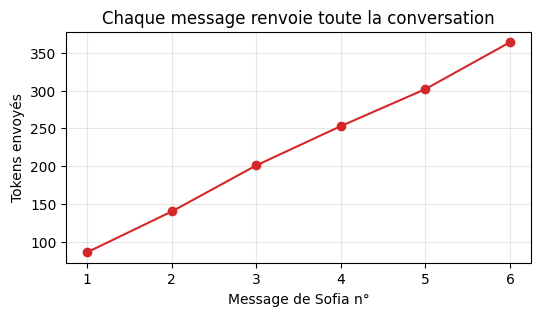

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3))
plt.plot(range(1, len(tokens_envoyes) + 1), tokens_envoyes, marker="o", color="tab:red")
plt.title("Chaque message renvoie toute la conversation")
plt.xlabel("Message de Sofia n°"); plt.ylabel("Tokens envoyés"); plt.grid(alpha=0.3)
plt.show()

**La courbe monte à chaque message** : on renvoie toute la conversation. Avec 50 échanges, chaque question envoie environ 50 fois plus de tokens que la première.
**À savoir** : Le *cache de prompt* d'OpenAI peut faire baisser le prix de la partie déjà envoyée (selon le modèle et la requête), mais le volume, lui, grandit toujours.
Et même si les modèles récents acceptent des centaines de milliers de tokens, un historique trop long **ralentit** les réponses et **noie** les informations importantes.

### Solution 1 : la fenêtre glissante

On ne garde que les **N derniers messages**. C'est simple et le coût est fixe... mais Léa **oublie le début**. Regardons ce que le modèle reçoit vraiment :

In [14]:
def fenetre_glissante(messages, n=2):
    """Garde le prompt système + les n derniers messages."""
    return [messages[0]] + messages[1:][-n:]

question = {"role": "user", "content": "Rappelez-moi ma pointure ?"}
courte = fenetre_glissante(historique) + [question]

print("Ce que le modèle reçoit :")
for m in courte:
    print(f"   [{m['role']}] {m['content'][:80]}...".replace("\n", " "))

r = client.chat.completions.create(model=MODELE, messages=courte)
print("\nLéa :", r.choices[0].message.content)

Ce que le modèle reçoit :
   [system] Tu es Léa, conseillère de vente de MégaShop, boutique en ligne d'articles du quo...
   [user] Et pour ma sœur, une idée de cadeau à moins de 50 € ? Elle adore le sport....
   [assistant] Pour votre sœur sportive, je vous recommande nos écouteurs sans fil, parfaits po...
   [user] Rappelez-moi ma pointure ?...

Léa : Pourriez-vous me rappeler votre nom ou votre numéro de commande, s’il vous plaît ? Ainsi, je pourrai vérifier votre pointure rapidement.


Le « 42 » n'est plus dans ce que le modèle reçoit : Léa **ne peut pas** le connaître. Elle redemande (ou, pire, elle devine).

### Solution 2 : le résumé

On demande au LLM de **résumer** les anciens messages en quelques lignes, puis on remplace l'historique par ce résumé et les derniers messages. Léa garde l'essentiel, pour beaucoup moins de tokens :

In [15]:
def resumer(messages):
    """Demande au LLM un résumé court de la conversation, centré sur le client."""
    texte = "\n".join(f"{m['role']} : {m['content']}" for m in messages[1:])
    r = client.chat.completions.create(model=MODELE, messages=[{"role": "user", "content":
        "Résume cette conversation de vente en 3 lignes. Garde les infos sur le client "
        "(prénom, tailles, goûts, budget) :\n\n" + texte}])
    return r.choices[0].message.content

resume = resumer(historique)
print("Résumé :", resume)

Résumé : Sofia chausse du 42 et recherche des baskets blanches pour accompagner un jean, avec un budget maximum de 130 €. Elle préfère une livraison en point relais. Elle souhaite également un cadeau sportif à moins de 50 € pour sa sœur.


In [16]:
compacte = [historique[0], {"role": "system", "content": f"Résumé de la conversation : {resume}"},
            *historique[-2:], question]
r = client.chat.completions.create(model=MODELE, messages=compacte)
print("Léa :", r.choices[0].message.content)

Léa : Vous chaussez du 42, n’est-ce pas ? Souhaitez-vous que je vous montre les baskets blanches disponibles dans cette taille ?


### Le même message, trois stratégies

<p align="center"><img src="assets/diagrams/nb1_trois_strategies.png" alt="Trois stratégies pour la même question : l'historique complet connaît la pointure, la fenêtre glissante l'a oubliée, le résumé la garde pour moins de tokens" width="860"></p>

On compte les tokens **du même texte** avec `tiktoken` pour comparer à armes égales :

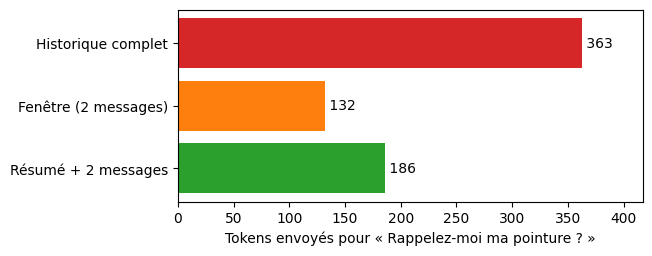

L'API annonce 209 tokens pour le résumé : elle ajoute quelques tokens de mise en forme par message.


In [17]:
def compter(messages):
    return sum(len(encodeur.encode(m["content"])) for m in messages)

strategies = {"Historique complet": historique + [question],
              "Fenêtre (2 messages)": courte,
              "Résumé + 2 messages": compacte}
tailles = {nom: compter(msgs) for nom, msgs in strategies.items()}

plt.figure(figsize=(6, 2.5))
plt.barh(list(tailles), list(tailles.values()), color=["tab:red", "tab:orange", "tab:green"])
for i, t in enumerate(tailles.values()):
    plt.text(t, i, f" {t}", va="center")
plt.xlim(0, max(tailles.values()) * 1.15); plt.gca().invert_yaxis(); plt.xlabel("Tokens envoyés pour « Rappelez-moi ma pointure ? »")
plt.show()
print(f"L'API annonce {r.usage.prompt_tokens} tokens pour le résumé : elle ajoute quelques tokens de mise en forme par message.")

**À retenir**

| Stratégie | Avantage | Inconvénient |
|---|---|---|
| Historique complet | Rien n'est perdu | Coût et lenteur qui augmentent |
| Fenêtre glissante | Simple, coût fixe | Oublie le début (ici, la pointure) |
| Résumé | Garde l'essentiel, peu de tokens | Un appel en plus, des détails perdus |

En pratique, on **combine** souvent : un résumé des anciens messages + les derniers messages en entier.

---
## Étape 7 · La mémoire long terme : un profil client

**Objectif** : que Léa se souvienne de Sofia **la semaine prochaine**, dans une nouvelle conversation.

L'historique et le résumé sont du **texte libre**. Pour une mémoire durable, on préfère une **fiche client structurée**, comme dans un logiciel de gestion client (CRM) : prénom, pointure, budget...

**Piège** : « je cherche des baskets blanches » ne veut pas dire « j'adore le blanc », et « ma sœur adore le sport » parle de la sœur, pas de Sofia. Une bonne mémoire distingue ce que le client **a dit** de ce qu'on **suppose** : d'où une case `a_confirmer`.

Le LLM va **remplir cette fiche** à partir de la conversation. **Pydantic**, la bibliothèque Python de référence pour décrire et **valider** des données, garantit le format.

In [18]:
from pydantic import BaseModel, Field

class ProfilClient(BaseModel):
    """La fiche client que Léa garde en mémoire d'une visite à l'autre."""
    prenom: str | None = Field(description="Prénom du client")
    pointure: int | None = Field(description="Pointure de chaussures du client")
    budget_max: float | None = Field(description="Budget maximum en euros")
    gouts: list[str] = Field(description="Goûts durables affirmés par le client (« j'adore le bleu »), pas ceux de ses proches")
    a_confirmer: list[str] = Field(description="Goûts supposés, cités pour un seul achat (ex. la couleur des baskets cherchées)")

### En Python pur : les « sorties structurées » d'OpenAI

`client.chat.completions.parse()` oblige le LLM à répondre **exactement** au format de la classe. Pydantic vérifie ensuite les types : la pointure est bien un **nombre entier**, les couleurs une **liste**...

In [19]:
messages_client = "\n".join(m["content"] for m in historique if m["role"] == "user")
CONSIGNE = ("Remplis la fiche du client à partir de ses messages. N'invente rien. "
            "Un goût cité pour un seul achat va dans a_confirmer, pas dans gouts.")

r = client.chat.completions.parse(
    model=MODELE, temperature=0,
    response_format=ProfilClient,                    # le format imposé
    messages=[{"role": "system", "content": CONSIGNE},
              {"role": "user", "content": messages_client}],
)
profil = r.choices[0].message.parsed                 # un vrai objet Python, déjà validé
print(profil.model_dump_json(indent=2))
print("\nPointure + 1 =", profil.pointure + 1, "(c'est bien un nombre)")

{
  "prenom": "Sofia",
  "pointure": 42,
  "budget_max": 130.0,
  "gouts": [],
  "a_confirmer": [
    "baskets blanches"
  ]
}

Pointure + 1 = 43 (c'est bien un nombre)


Et si la donnée a une mauvaise forme ? Pydantic la **refuse** :

In [20]:
from pydantic import ValidationError

try:
    ProfilClient(prenom="Sofia", pointure="grande", budget_max=None, gouts=[], a_confirmer=[])
except ValidationError as erreur:
    print("Fiche refusée :", erreur.errors()[0]["loc"][0], "→", erreur.errors()[0]["msg"])

Fiche refusée : pointure → Input should be a valid integer, unable to parse string as an integer


**Attention** : Pydantic garantit la **forme** (une pointure est un nombre), **pas la vérité** : si le LLM attribue à Sofia le goût de sa sœur, la fiche reste « valide ».
D'où la case `a_confirmer` et la règle : **en cas de doute, on demande au client**.

### Avec LangChain

`with_structured_output()` fait la même chose, quel que soit le fournisseur de LLM.

In [21]:
extracteur = llm.with_structured_output(ProfilClient)
profil_lc = extracteur.invoke(f"{CONSIGNE}\n\n{messages_client}")
print(profil_lc)

prenom='Sofia' pointure=42 budget_max=130.0 gouts=[] a_confirmer=['baskets blanches']


### Une semaine plus tard...

Sofia revient. C'est une **nouvelle conversation** : l'historique est vide. Mais on glisse sa fiche dans le prompt système, avec une consigne : **faire confirmer** ce qui est incertain.

In [22]:
def accueillir(fiche):
    """Nouvelle conversation : seule la fiche (si elle existe) sert de mémoire."""
    systeme = SYSTEME
    if fiche:
        systeme += (f"\n\nFiche du client (mémoire long terme) : {fiche.model_dump_json()}"
                    "\nAvant d'utiliser un point de « a_confirmer », demande au client de le confirmer.")
    r = client.chat.completions.create(model=MODELE, messages=[
        {"role": "system", "content": systeme},
        {"role": "user", "content": "Re-bonjour ! Vous auriez des baskets pour moi ?"}])
    return r.choices[0].message.content

print("Léa :", accueillir(profil))

Léa : Bonjour Sofia, je me rappelle que vous aviez mentionné des baskets blanches, est-ce toujours ce que vous recherchez ? Nous avons plusieurs modèles très confortables dans votre pointure 42 et dans votre budget de 130€. Souhaitez-vous que je vous en propose quelques-uns ?


Léa reconnaît Sofia et adapte son conseil **sans que Sofia ait rien répété**, et elle vérifie ce qui n'était qu'une supposition.

### Le droit à l'oubli

Sofia demande la suppression de ses données. On efface sa fiche, et Léa ne peut plus personnaliser :

In [23]:
profil = None                                   # en production : supprimer la fiche de la base
print("Léa :", accueillir(profil))

Léa : Bonjour ! Oui, nous avons un large choix de baskets, des modèles classiques aux plus tendance. Souhaitez-vous une marque ou un style en particulier ?


Le parcours complet, de la conversation à la visite suivante :

<p align="center"><img src="assets/diagrams/nb1_profil_client.png" alt="De la conversation à la fiche client : le LLM remplit la fiche ProfilClient validée par Pydantic, la fiche est relue une semaine plus tard dans le prompt système, et le droit à l'oubli l'efface" width="1000"></p>

**À retenir**
- La **mémoire long terme** se stocke **hors du LLM**, idéalement sous forme **structurée** (une fiche, une base de données).
- **Pydantic** décrit le format attendu et **garantit la forme**, pas la vérité : ce qui est supposé doit être **confirmé** par le client.
- **Attention** : Une fiche client contient des **données personnelles** : en production, il faut respecter le RGPD (consentement, durée de conservation, droit à l'oubli comme ci-dessus).

---
## Synthèse : les 4 mémoires d'un assistant

<p align="center"><img src="assets/diagrams/nb1_quatre_memoires.png" alt="Les quatre mémoires d'un assistant classées par durée de vie" width="940"></p>

**Les 3 idées à garder**
1. Un LLM **prédit des tokens** : il ne « sait » rien de ta boutique et ne se souvient de rien.
2. La mémoire, **c'est ton code** qui la gère, et elle a un coût.
3. Pour une mémoire durable et fiable, on **structure** les données (Pydantic).

**Repères**

| Concept | Python pur | Framework |
|---|---|---|
| Appeler un LLM | `client.chat.completions.create()` | `ChatOpenAI().invoke()` (LangChain) |
| Mémoire par conversation | une liste `historique` | `checkpointer` + `thread_id` (LangGraph) |
| Sortie structurée | `client.chat.completions.parse()` | `with_structured_output()` (LangChain) |

**Prochain notebook** : Léa sait parler, mais elle ne connaît pas le stock. Elle va apprendre à **utiliser des outils** (stock, livraison, retours) : c'est le passage de l'assistant à l'**agent**.